In [1]:
# 工作代码在Notebook中保留，导出PDF时隐藏。
from pathlib import Path
import sys
from IPython.display import Markdown, Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data-Project1/train_data.csv").exists())
sys.path.insert(0, str(ROOT / "scripts/report"))
from report_utils import load_evidence, results_table, make_comparison, verify_and_predict, write_manifest
ctx = load_evidence()
scores = verify_and_predict(ctx)  # 验证选定后，仅重新拟合最终SVM


# 实验一：文本分类

在这次的任务中，我们要做的是使用给定的训练数据训练出一个模型，再用这个模型对unlabeled data进行分类。模型接收文本向量，输出0-9中的一个类别编号。训练时，我们使用的是有标签数据：模型根据预测与真实标签计算损失，再由优化算法更新参数。预测是否正确可以用于统计准确率，但无标签数据没有真实答案，不能用来判断True或False，也不能据此更新模型。

## 1. 第一个问题：训练集应该如何划分？

我们现在有训练数据，却没有单独的验证集。这个问题比较容易解决：将train_data.csv看作已有的标注数据全集，重新划分出训练集、验证集和本地测试集。训练集负责学习参数，验证集负责比较模型和超参数，测试集负责最终评价；课程提供的无标签数据仍然留给最后的预测。

困难的地方在于，划分的比例是多少？由于很难找到一个绝对好的比例，我先选择80:10:10作为基线，再取85:5:10和90:5:5进行比较。原始数据共有7368条标注文本、2457条无标签文本，10个类别各有705-747条；原文长度中位数为1139字符，无缺失和完全重复文本。为了尽量保持类别比例，我们采用分层划分，并固定随机种子42。

| 划分 | 训练:验证:测试 | 训练数 | 验证数 | 测试数 |
| --- | --- | --- | --- | --- |
| A | 80:10:10 | 5894 | 737 | 737 |
| B | 85:5:10 | 6262 | 369 | 737 |
| C | 90:5:5 | 6630 | 369 | 369 |

## 2. 第二个问题：哪些文本信息值得保留？

只要看一下数据本身就会发现，这些新闻组文本具有信件式的结构，带有Subject、From等字段。按照我们的常识，subject大概率和文本类别相关；author也可能提供一些线索。所以，与其只把整段文本一股脑地塞进去，我们可以先尝试保留不同的信息，再通过实验判断这种想法是否有效。

按照这个思路，我们比较四种情况：raw保留原文；body_only移除已知头字段、保留正文；subject_body保留标题和正文；subject_body_author再加入作者。清洗沿用逐行规则，仍可能留下未知头字段、引用和签名；作者信息也可能使模型依赖来源，需要在结果中一起讨论。

这四种文本都使用TF-IDF向量化，raw同样需要这一步。TF-IDF用词频表示文档内容，用IDF降低常见词的权重，再通过L2归一化减轻文本长度对向量尺度的影响。参数为min_df=2、max_df=0.95、max_features=20000；词表和IDF只在训练集上拟合。同一划分的四种版本使用相同样本，避免比较时同时改变数据和处理方法。

## 3. 准备好数据之后，我们来选择模型

我选择的模型分别是Linear SVM和MLP。Linear SVM在高维空间中寻找最大间隔的线性分类边界，适合作为稀疏文本特征的基线；MLP通过隐藏层和ReLU学习非线性关系，可以用来观察更复杂的模型是否带来提升。两者输入的是同一套TF-IDF向量，因此这里比较的是线性与非线性模型，而不是高维与低维。

| 模型 | 候选参数与训练设置 |
| --- | --- |
| Linear SVM | C∈{0.1, 1, 10}；max_iter=5000 |
| MLP | h∈{(50,), (100,), (100,50)}；α∈{0.0001, 0.001} |

MLP使用Adam、初始学习率0.001，训练300轮，不早停。三种划分、四种文本和九种模型配置共108组。我们先比较验证Accuracy，并列时比较宏F1；测试分数不参与排序。下表是两个模型分别选出的配置，均为85:5:10、标题+正文+作者，F1为宏平均。

In [2]:
display(Markdown(results_table(ctx)))

| 模型 | 文本 | 验证选定参数 | Val Acc% | Val F1% | Test Acc% | Test F1% |
| --- | --- | --- | --- | --- | --- | --- |
| SVM | 标题+正文+作者 | C=1 | 96.48 | 96.51 | 94.03 | 94.08 |
| MLP | 标题+正文+作者 | h=(50,), α=0.001 | 96.21 | 96.25 | 93.62 | 93.67 |

## 4. 从曲线和结果中回答前面的问题

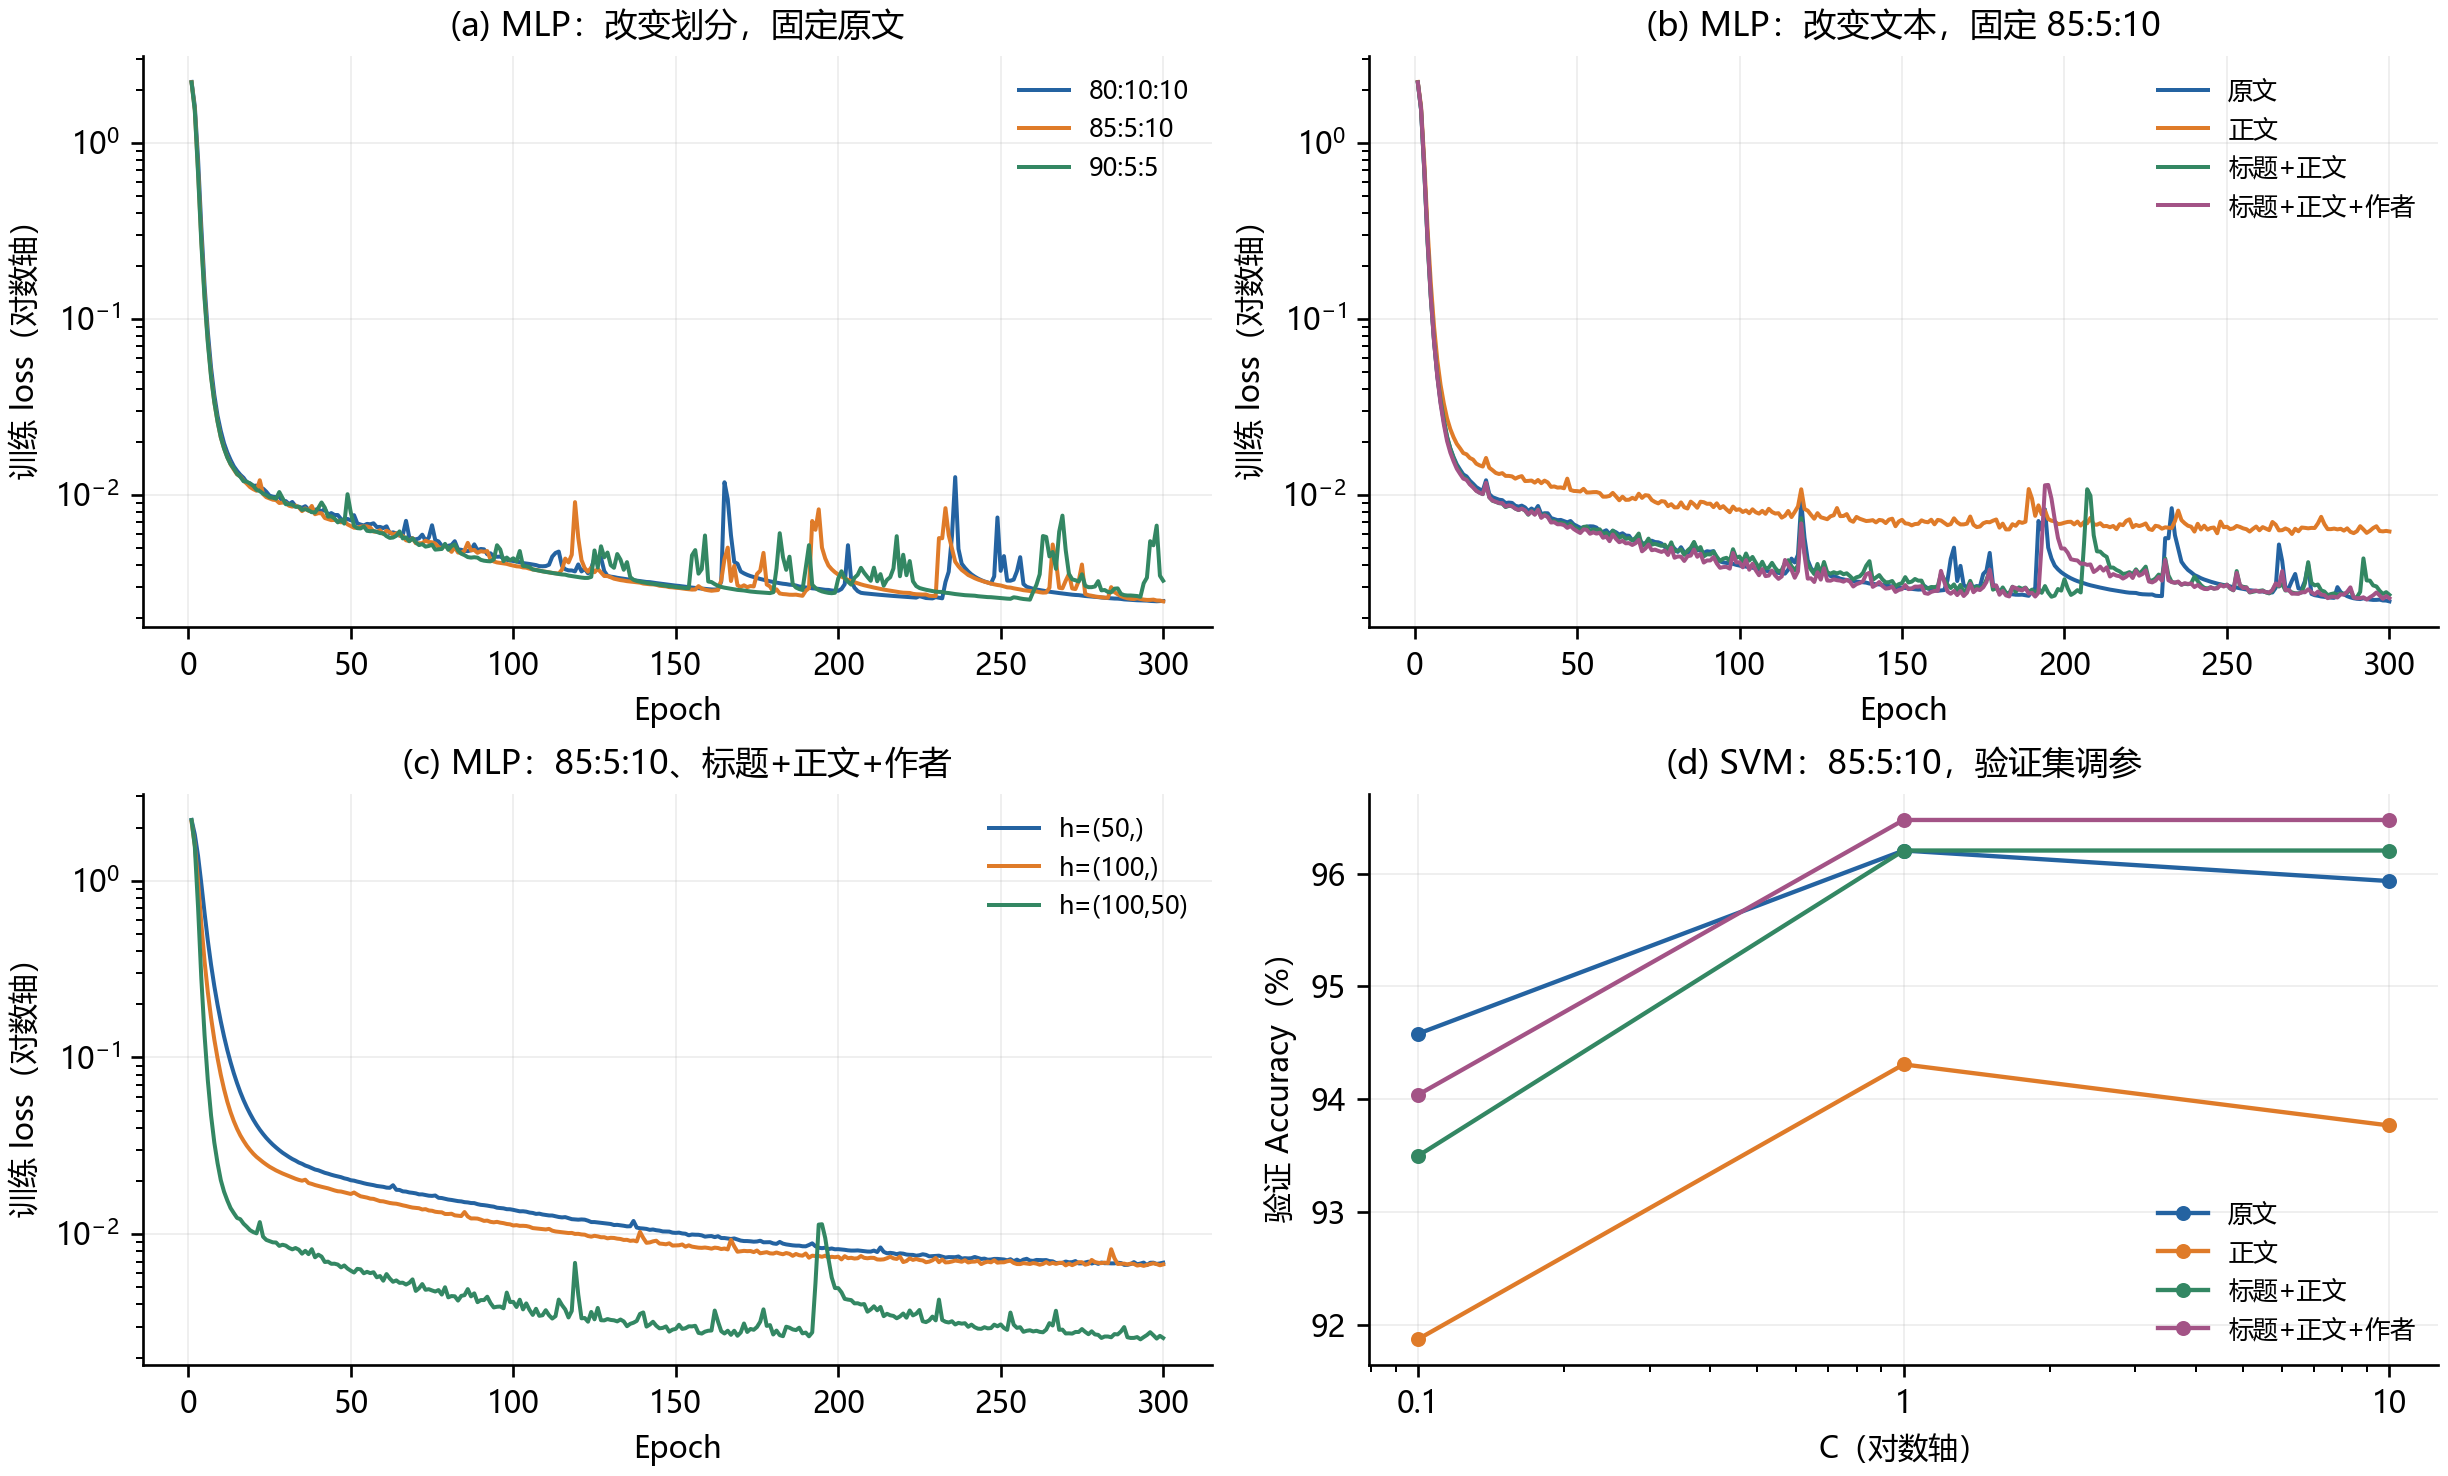

In [3]:
figure = make_comparison(ctx)
display(Image(filename=str(figure)))

图1：(a)固定MLP原文输入、h=(100,50)、α=0.001，比较划分；(b)固定85:5:10及相同MLP参数，比较四种文本；(c)固定85:5:10、标题+正文+作者及α=0.001，比较隐藏层；(d)固定85:5:10，比较SVM的C与文本。前三图都是日志中的真实训练loss，使用对数纵轴，没有平滑；最后一图是验证准确率，不是loss。

先看数据划分。固定SVM C=1和标题+正文+作者，80:10:10、85:5:10、90:5:5的验证Accuracy分别为94.98%、96.48%、94.85%。这样看，85:5:10在这次比较中更好，但训练样本增加并没有带来单调提升。原因是划分改变时，验证样本也变了；A/B的本地测试集相同，C不同，不能仅凭这些数字断言某个比例普遍最好。

再看文本处理。固定85:5:10和SVM C=1，body_only、subject_body、raw、subject_body_author的验证Accuracy分别为94.31%、96.21%、96.21%、96.48%。保留标题后结果有所提升，符合我们开始时的猜测；加入作者后，验证集又多预测正确了1条。不过，369条验证样本中1条就约占0.27个百分点，这个提升很小，也可能与作者和类别的关联有关，还需要按作者分组或更换随机种子验证。

最后看模型本身。图中的MLP loss总体下降，但更低的训练loss不能直接说明分类效果更好。固定85:5:10、标题+正文+作者和α=0.001，隐藏层为(50,)、(100)、(100,50)时，验证Accuracy为96.21%、95.93%、94.04%。增加神经元和层数并没有得到更好的结果。复杂模型可能更依赖优化与正则化，也有过拟合风险；现有日志没有逐轮验证loss，因此不能仅凭训练曲线确定过拟合发生的轮次。SVM在这次实验中略优于MLP，也说明高维文本特征下，线性模型已经能有效区分类别。

## 5. 最后，我们选择什么方案？

In [4]:
display(Markdown(
    "根据验证集的比较，我最后选择85:5:10、subject_body_author和Linear SVM(C=1)。"
    f"验证Accuracy为{100*scores['val_acc']:.2f}%，本地测试Accuracy为{100*scores['test_acc']:.2f}%，"
    f"宏F1为{100*scores['test_f1']:.2f}%，宏Precision/Recall为"
    f"{100*scores['test_precision']:.2f}%/{100*scores['test_recall']:.2f}%。"
    f"重新拟合只使用6262条训练样本，TF-IDF维度为{scores['n_features']}；最终对2457条无标签文本输出了无表头预测CSV。"))

根据验证集的比较，我最后选择85:5:10、subject_body_author和Linear SVM(C=1)。验证Accuracy为96.48%，本地测试Accuracy为94.03%，宏F1为94.08%，宏Precision/Recall为94.17%/94.04%。重新拟合只使用6262条训练样本，TF-IDF维度为20000；最终对2457条无标签文本输出了无表头预测CSV。

需要说明的是，原有训练脚本为每个候选都记录了测试指标，这次报告属于对已有实验的回顾分析，不能说测试集从未被查看。我们的排序只依据验证结果；后续更严格的做法是先锁定方案，再评价独立测试集。Notebook保留读取、校验、画图与预测代码，依赖版本和输入摘要保存在evidence_manifest.json中。本次重新拟合核验了最终SVM；MLP结果及loss曲线来自既有日志，未重新训练。

In [5]:
write_manifest(ctx)